In [714]:
from typing import List
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import copy

import cvxpy as cp

from Components.RecedingHorizon import RecedingHorizon
from Components.System import SimpleSquareExample
from Components.Model import SquareCoarseModel
from Components.Controllers import LTI_LQRc_RHG

from Components.Solver import fbrs

In [715]:
# Reload scripts when executed
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Symmetric aquifer without constraints

In [716]:
parameter_file = "Components/Setup/sym_aquifer.json"

In [717]:
# Initialize Model
model = SquareCoarseModel(parameter_file)

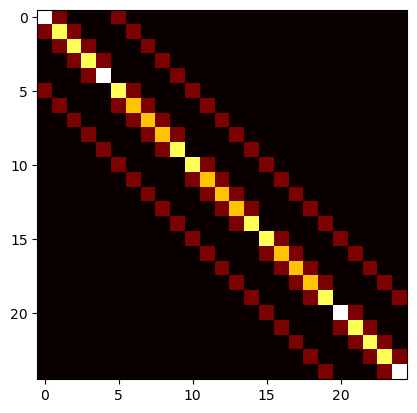

In [718]:
plt.imshow(model.A.toarray(), cmap='hot', interpolation='nearest')

In [719]:
eig = np.linalg.eigvals(model.A.toarray())
np.max(eig), np.min(eig)

(np.float64(1.0000000000000002), np.float64(0.07740133286877682))

In [720]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)

In [721]:
np.max(np.linalg.eigvals(controller.A_tilde.toarray()[-25:]))

np.complex128(0.9999999999999998+0j)

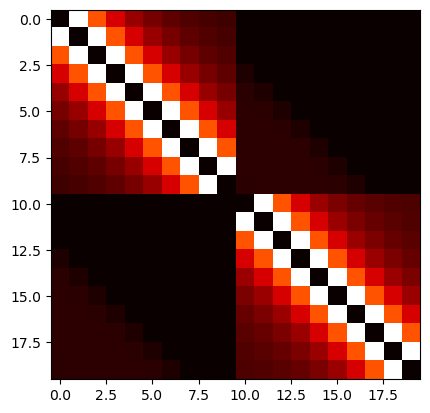

In [722]:
plt.imshow(controller.F.toarray(), cmap='hot', interpolation='nearest')

In [723]:
eig = np.linalg.eigvals(controller.F.toarray())
np.max(eig), np.min(eig)

(np.float64(0.9700290978812403), np.float64(-0.3428387323064055))

In [724]:
eig = np.linalg.eigvals((0.5*(controller.F.T + controller.F)).toarray())
np.max(eig), np.min(eig)

(np.float64(0.971552461848591), np.float64(-0.34293778879090187))

In [725]:
ctrl_wo_csrt = copy.deepcopy(controller)

In [726]:
if True:
    ctrl_wo_csrt.H = sp.csr_array(np.zeros_like(controller.H.toarray()))
    ctrl_wo_csrt.h_x_0 = sp.csr_array(np.zeros_like(controller.h_x_0.toarray()))
    ctrl_wo_csrt.h = sp.csr_array(np.zeros_like(controller.h.toarray()))

In [727]:
x_0 = 10. * np.ones((25,1))
u_opt = ctrl_wo_csrt.step(x_0)
u_opt

array([[-6466.64332885, -4411.31144429],
       [-7052.31658073, -5851.98701874],
       [-2136.94755695, -3082.11259638],
       [ 3165.27141645,   976.28984964],
       [ 3509.47728802,  2289.03828705],
       [-1286.99718152,  -246.05147227],
       [-6216.90065821, -3891.03133944],
       [-6306.48385375, -5002.35014358],
       [-1668.95103255, -2682.36457864],
       [ 2655.54704538,   467.05314694]])

In [728]:
u_analytic = np.linalg.inv((controller.F).toarray()) @ (-(controller.f_x @ x_0 + controller.f))
u_analytic

array([[-6466.64332885],
       [-7052.31658073],
       [-2136.94755694],
       [ 3165.27141646],
       [ 3509.47728803],
       [-1286.99718152],
       [-6216.90065821],
       [-6306.48385375],
       [-1668.95103255],
       [ 2655.54704539],
       [-4411.31144429],
       [-5851.98701874],
       [-3082.11259638],
       [  976.28984964],
       [ 2289.03828705],
       [ -246.05147227],
       [-3891.03133944],
       [-5002.35014358],
       [-2682.36457864],
       [  467.05314694]])

In [729]:
np.hstack([u_analytic[sum(controller.nu_v[:v])*controller.K:sum(controller.nu_v[:v+1])*controller.K]\
                .reshape(controller.K,controller.nu_v[v]) for v in range(controller.n_players)]) \
                    - u_opt

array([[-4.94401320e-09, -3.00133252e-10],
       [-2.64481059e-09, -2.69210432e-10],
       [ 2.55931809e-09,  1.45064405e-10],
       [ 5.27052180e-09,  3.16504156e-10],
       [ 2.72120815e-09,  2.04181561e-10],
       [-2.54544830e-09,  6.34940989e-11],
       [-5.17138687e-09, -1.59161573e-11],
       [-2.56204657e-09,  7.09405867e-11],
       [ 2.56250132e-09, -9.59516910e-11],
       [ 4.79394657e-09, -1.33923095e-10]])

# With constraints and different scale of F

In [730]:
F, f_x, f = controller.F.copy(), controller.f_x.copy(), controller.f.copy()

In [731]:
controller.F = F*1e1
controller.f_x = f_x*1e1
controller.f = f*1e1

In [732]:
x_0 = 10. * np.ones((25,1))
f_1 = sp.csr_array(controller.f_x @ x_0 + controller.f)
h = sp.csr_array(controller.h_x_0 @ x_0 + controller.h)

In [733]:
u_opt_1, _, _, out_1 = fbrs(controller.F.toarray(), f_1, controller.H.toarray(), h.toarray(), controller.u0, controller.v0)
out_1['eflag'], u_opt_1

(-1,
 array([[-2000.00000001],
        [-1999.99999998],
        [-1999.99999988],
        [-1984.43169523],
        [-2065.33737938],
        [-1907.8830145 ],
        [-2000.00000084],
        [ -885.07990325],
        [-2000.00000076],
        [-2000.00000037],
        [-1000.        ],
        [-1000.        ],
        [-1000.        ],
        [-1000.        ],
        [-1000.        ],
        [-1000.        ],
        [ -999.99999999],
        [ -999.99999998],
        [ -999.99999998],
        [ -999.99999999]]))

In [734]:
controller.F = F*1e0
controller.f_x = f_x*1e0
controller.f = f*1e0

In [735]:
x_0 = 10. * np.ones((25,1))
f_0 = sp.csr_array(controller.f_x @ x_0 + controller.f)
h = sp.csr_array(controller.h_x_0 @ x_0 + controller.h)

In [736]:
u_opt, U_dual, _, out = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), controller.u0, controller.v0)
out['eflag'], u_opt

(0,
 array([[-2.0000000e+03],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-2.6546131e-13],
        [-2.0000000e+03],
        [-2.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03],
        [-1.0000000e+03]]))

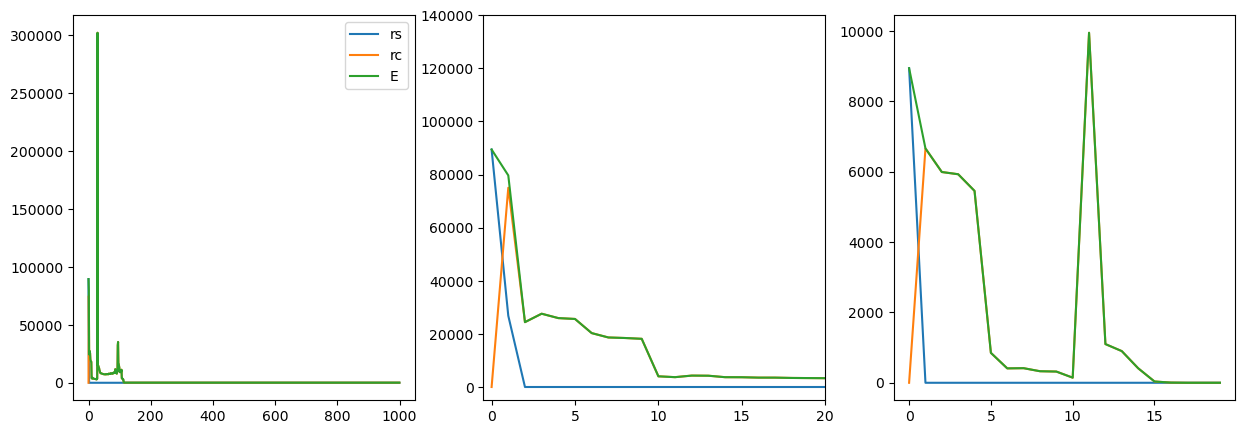

In [708]:
fig = plt.figure(figsize=(15,5))
# Plot non converging
ax = fig.add_subplot(1, 3, 1)
ax.plot(np.array([np.linalg.norm(rs) for rs in out_1['rs']]), label='rs')
ax.plot(np.array([np.linalg.norm(rc) for rc in out_1['rc']]), label='rc')
ax.plot(np.array(out_1['E']), label='E')
ax.legend()

# Zoom
ax = fig.add_subplot(1, 3, 2)
ax.plot([np.linalg.norm(rs) for rs in out_1['rs']])
ax.plot([np.linalg.norm(rc) for rc in out_1['rc']])
ax.plot(out_1['E'])
ax.set_ylim([-5000,140000])
ax.set_xlim([-0.5,20])

# Plot converging
ax = fig.add_subplot(1, 3, 3)
ax.plot([np.linalg.norm(rs) for rs in out['rs']])
ax.plot([np.linalg.norm(rc) for rc in out['rc']])
ax.plot(out['E'])

plt.show()

In [678]:
out_1['E'][-5:], out['E'][-5:]

([np.float64(106.8251128195391),
  np.float64(106.09003768746157),
  np.float64(109.30084117561756),
  np.float64(109.26681284964857),
  np.float64(106.58198073649186)],
 [np.float64(36.614175590914165),
  np.float64(4.990925978448903),
  np.float64(0.16421028522272474),
  np.float64(0.00019728279681798097),
  np.float64(2.867479880589407e-10)])

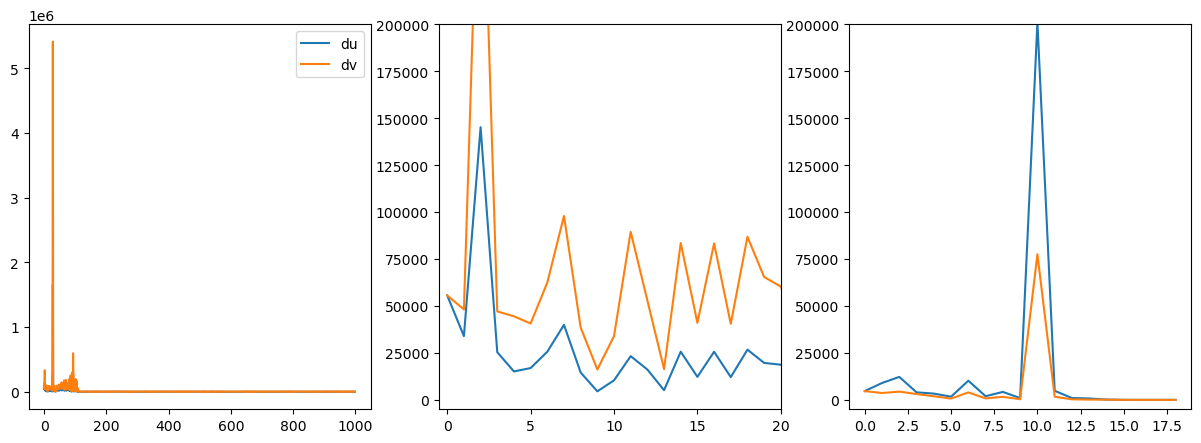

In [713]:
fig = plt.figure(figsize=(15,5))
# Plot non converging
ax = fig.add_subplot(1, 3, 1)
ax.plot(np.array([np.linalg.norm(du) for du in out_1['du']]), label='du')
ax.plot(np.array([np.linalg.norm(dv) for dv in out_1['dv']]), label='dv')
ax.legend()

# Zoom
ax = fig.add_subplot(1, 3, 2)
ax.plot([np.linalg.norm(du) for du in out_1['du']])
ax.plot([np.linalg.norm(dv) for dv in out_1['dv']])
ax.set_ylim([-5000,200000])
ax.set_xlim([-0.5,20])

# Plot converging
ax = fig.add_subplot(1, 3, 3)
ax.plot([np.linalg.norm(du) for du in out['du']])
ax.plot([np.linalg.norm(dv) for dv in out['dv']])
ax.set_ylim([-5000,200000])

plt.show()

# Real failure case

In [740]:
parameter_file = "Components/Setup/aquifer_parameters.json"

In [741]:
# Initialize Model
model = SquareCoarseModel(parameter_file)

In [742]:
# Initialize Controller
controller = LTI_LQRc_RHG(
    parameter_file,
    model.A.toarray(), [B.toarray() for B in model.B_v], model.C,
    model.H_x, model.h_x, model.H_u_v, model.h_u_v,
    Q_v = None, R_v = None, M_v = [G.toarray() for G in model.Gamma_v], L_v = [Xi for Xi in model.Xi_v],
    solver='fbrs'
)

In [745]:
data = np.load('debug_data.npz')
x_0 = data['x0']
u0 = data['u0']
v0 = data['v0']

In [746]:
f_0 = sp.csr_array(controller.f_x @ x_0 + controller.f)
h = sp.csr_array(controller.h_x_0 @ x_0 + controller.h)

In [ ]:
u_opt, U_dual, _, out = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), u0, v0)
out['eflag'], u_opt

(-1,
 array([[-2.70669355e+02],
        [-8.76796595e+01],
        [-2.16145065e+01],
        [ 1.24104218e-08],
        [-4.25412010e+02],
        [ 1.09287518e-08],
        [-7.60795565e+02],
        [ 2.38883019e-09],
        [-5.79423974e+02],
        [ 3.12306985e-09],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-9.65570902e+02],
        [ 1.52304027e-08],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-2.53185889e+02],
        [-3.75308654e-08],
        [-7.45770355e+01],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+0

In [750]:
v_0 = np.zeros_like(v0)
u_opt_zeroi, U_dual_zeroi, _, out_zeroi = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), u0, v_0)
out_zeroi['eflag'], u_opt_zeroi

(0,
 array([[-2.28259371e+02],
        [-7.38002980e-15],
        [-9.32714189e-15],
        [-3.61993712e+02],
        [-3.22043738e+02],
        [ 8.61123576e-15],
        [ 8.60137942e-15],
        [ 9.76796558e-15],
        [ 6.64972208e-13],
        [-2.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-5.86759917e+02],
        [ 1.98652145e-12],
        [-7.45286745e+02],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-6.39065907e+02],
        [-5.01591900e+02],
        [-1.00000000e+03],
        [-2.53562980e+02],
        [-2.40397108e-12],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03

In [762]:
F = controller.F*1e-1
f_0_d = f_0*1e-1
u_opt_downf, U_dual_downf, _, out_downf = fbrs(F.toarray(), f_0_d, controller.H.toarray(), h.toarray(), u0, v0)
out_downf['eflag'], u_opt_downf

(0,
 array([[-3.07233461e+02],
        [-1.08438561e+02],
        [ 4.23097466e-17],
        [-3.75348636e-16],
        [-3.75495374e+02],
        [ 1.93108306e-15],
        [-7.36345236e+02],
        [ 3.23500460e-15],
        [-6.19008963e+02],
        [-1.21022116e-15],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-2.28044216e-15],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-8.38626414e-16],
        [ 1.84211301e-15],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-7.31880154e-16],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03

In [763]:
F_u = controller.F*1e1
f_0_u = f_0*1e1
u_opt_upf, U_dual_upf, _, out_upf = fbrs(F_u.toarray(), f_0_u, controller.H.toarray(), h.toarray(), u0, v0)
out_upf['eflag'], u_opt_upf

(0,
 array([[-2.48822250e+02],
        [-7.15249716e+01],
        [-2.43227541e+01],
        [-1.01189787e-13],
        [-4.50562136e+02],
        [ 3.72500749e-13],
        [-7.98110604e+02],
        [-2.20041376e-13],
        [-6.30747909e+02],
        [ 8.07749382e-14],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-3.55087272e+02],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [ 4.49267338e-13],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-3.84718406e+02],
        [ 3.09370740e-13],
        [-2.56055150e+02],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03],
        [-1.00000000e+03

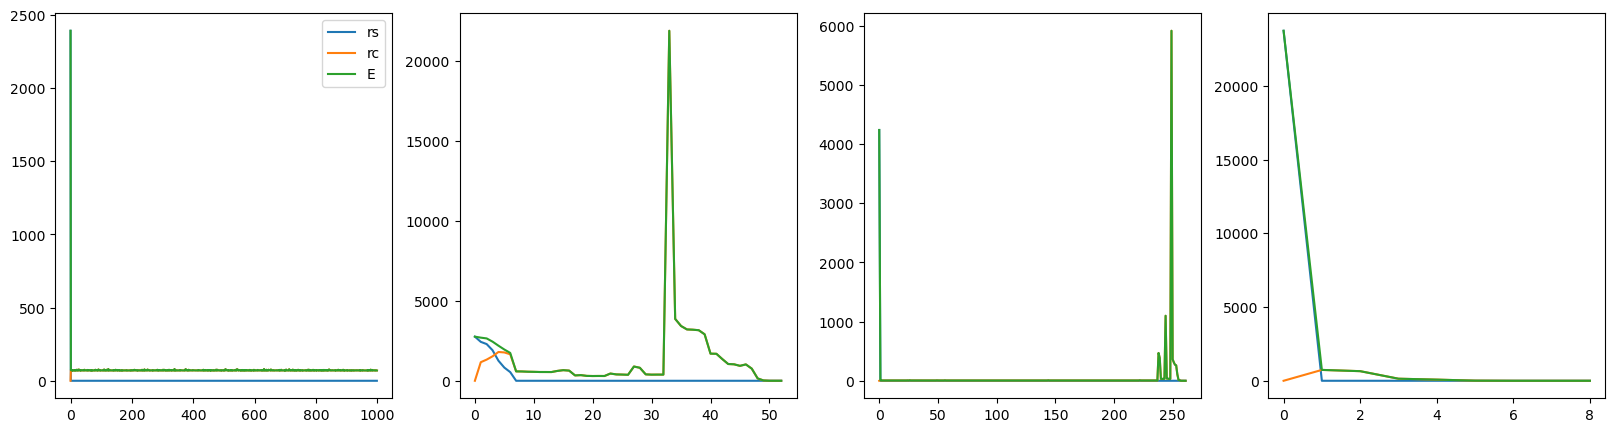

In [764]:
fig = plt.figure(figsize=(20,5))
# Plot non converging
ax = fig.add_subplot(1, 4, 1)
ax.plot(np.array([np.linalg.norm(rs) for rs in out['rs']]), label='rs')
ax.plot(np.array([np.linalg.norm(rc) for rc in out['rc']]), label='rc')
ax.plot(np.array(out['E']), label='E')
ax.legend()

# Plot zero-initial guess
ax = fig.add_subplot(1, 4, 2)
ax.plot([np.linalg.norm(rs) for rs in out_zeroi['rs']])
ax.plot([np.linalg.norm(rc) for rc in out_zeroi['rc']])
ax.plot(out_zeroi['E'])

# Plot downscaled F
ax = fig.add_subplot(1, 4, 3)
ax.plot([np.linalg.norm(rs) for rs in out_downf['rs']])
ax.plot([np.linalg.norm(rc) for rc in out_downf['rc']])
ax.plot(out_downf['E'])

# Plot upscaled F
ax = fig.add_subplot(1, 4, 4)
ax.plot([np.linalg.norm(rs) for rs in out_upf['rs']])
ax.plot([np.linalg.norm(rc) for rc in out_upf['rc']])
ax.plot(out_upf['E'])

plt.show()

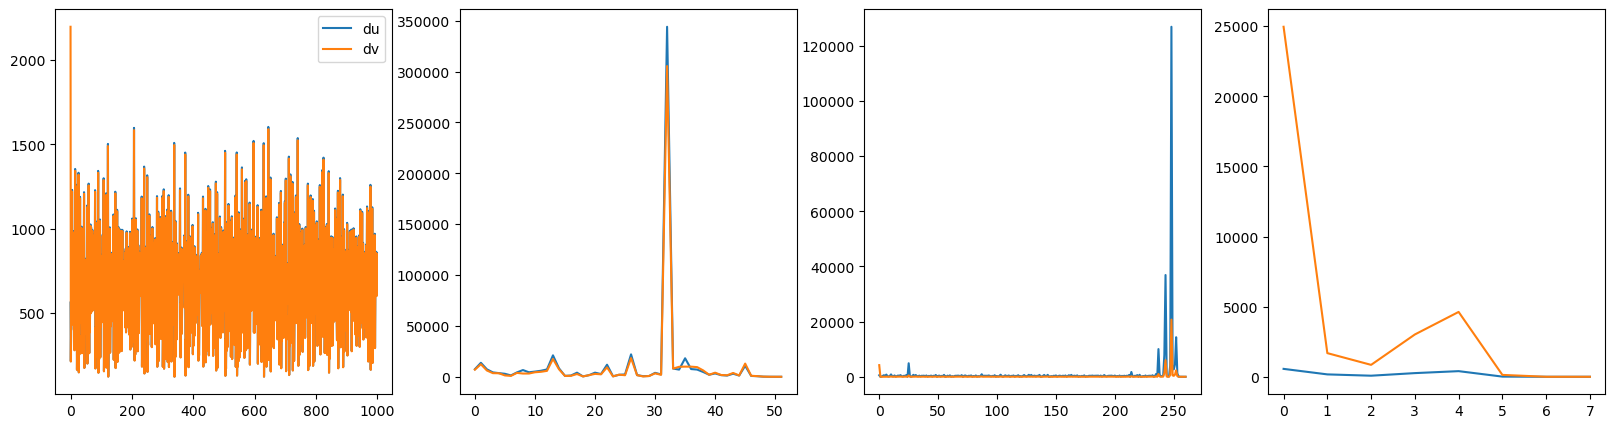

In [766]:
fig = plt.figure(figsize=(20,5))
# Plot non converging
ax = fig.add_subplot(1, 4, 1)
ax.plot(np.array([np.linalg.norm(rs) for rs in out['du']]), label='du')
ax.plot(np.array([np.linalg.norm(rc) for rc in out['dv']]), label='dv')
ax.legend()

# Plot zero-initial guess
ax = fig.add_subplot(1, 4, 2)
ax.plot([np.linalg.norm(rs) for rs in out_zeroi['du']])
ax.plot([np.linalg.norm(rc) for rc in out_zeroi['dv']])

# Plot downscaled F
ax = fig.add_subplot(1, 4, 3)
ax.plot([np.linalg.norm(rs) for rs in out_downf['du']])
ax.plot([np.linalg.norm(rc) for rc in out_downf['dv']])

# Plot upscaled F
ax = fig.add_subplot(1, 4, 4)
ax.plot([np.linalg.norm(rs) for rs in out_upf['du']])
ax.plot([np.linalg.norm(rc) for rc in out_upf['dv']])

plt.show()

In [770]:
np.abs(u_opt_upf - u_opt_zeroi).max(), np.abs(u_opt_downf - u_opt_zeroi).max(), np.abs(u_opt_downf - u_opt_upf).max()

(np.float64(1999.9999999999986),
 np.float64(1999.9999999999986),
 np.float64(999.9999999999995))

In [772]:
np.hstack([u_opt_upf, u_opt_zeroi, u_opt_downf])

array([[-2.48822250e+02, -2.28259371e+02, -3.07233461e+02],
       [-7.15249716e+01, -7.38002980e-15, -1.08438561e+02],
       [-2.43227541e+01, -9.32714189e-15,  4.23097466e-17],
       [-1.01189787e-13, -3.61993712e+02, -3.75348636e-16],
       [-4.50562136e+02, -3.22043738e+02, -3.75495374e+02],
       [ 3.72500749e-13,  8.61123576e-15,  1.93108306e-15],
       [-7.98110604e+02,  8.60137942e-15, -7.36345236e+02],
       [-2.20041376e-13,  9.76796558e-15,  3.23500460e-15],
       [-6.30747909e+02,  6.64972208e-13, -6.19008963e+02],
       [ 8.07749382e-14, -2.00000000e+03, -1.21022116e-15],
       [-1.00000000e+03, -1.00000000e+03, -1.00000000e+03],
       [-1.00000000e+03, -1.00000000e+03, -1.00000000e+03],
       [-1.00000000e+03, -1.00000000e+03, -1.00000000e+03],
       [-3.55087272e+02, -5.86759917e+02, -1.00000000e+03],
       [-1.00000000e+03,  1.98652145e-12, -1.00000000e+03],
       [-1.00000000e+03, -7.45286745e+02, -1.00000000e+03],
       [ 4.49267338e-13, -1.00000000e+03

In [795]:
u_opt_upf_1, U_dual_upf_1, _, out_upf_1 = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), u_opt_upf, U_dual_upf)

In [796]:
u_opt_downf_1, U_dual_downf_1, _, out_downf_1 = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), u_opt_downf, U_dual_downf)

In [797]:
u_opt_zeroi_1, U_dual_zeroi_1, _, out_zeroi_1 = fbrs(controller.F.toarray(), f_0, controller.H.toarray(), h.toarray(), u_opt_zeroi, U_dual_zeroi)

In [799]:
np.set_printoptions(linewidth=np.inf)
np.hstack([u_opt_upf, u_opt_zeroi, u_opt_downf, u_opt_upf_1, u_opt_zeroi_1, u_opt_downf_1])

array([[-2.48822250e+02, -2.28259371e+02, -3.07233461e+02, -2.48822250e+02, -2.28259371e+02, -3.07233461e+02],
       [-7.15249716e+01, -7.38002980e-15, -1.08438561e+02, -7.15249716e+01, -7.38002980e-15, -1.08438561e+02],
       [-2.43227541e+01, -9.32714189e-15,  4.23097466e-17, -2.43227541e+01, -9.32714189e-15, -9.63780658e-15],
       [-1.01189787e-13, -3.61993712e+02, -3.75348636e-16,  1.97081664e-12, -3.61993712e+02, -8.91975414e-14],
       [-4.50562136e+02, -3.22043738e+02, -3.75495374e+02, -4.50562136e+02, -3.22043738e+02, -3.75495374e+02],
       [ 3.72500749e-13,  8.61123576e-15,  1.93108306e-15,  5.46786721e-12,  8.61123576e-15, -1.54720599e-13],
       [-7.98110604e+02,  8.60137942e-15, -7.36345236e+02, -7.98110604e+02,  8.60137942e-15, -7.36345236e+02],
       [-2.20041376e-13,  9.76796558e-15,  3.23500460e-15,  5.50950258e-12,  9.76796558e-15, -1.75436204e-13],
       [-6.30747909e+02,  6.64972208e-13, -6.19008963e+02, -6.30747909e+02,  6.64972208e-13, -6.19008963e+02],
 

We don't find the same solutions...